# Lab: exploratory analysis of house sales

One row is one house sale in Ames, Iowa, recorded between 2006 and 2010. The target is `SalePrice`, in US dollars. The client is a local real estate agency: it wants a price model, and it wants to know what in the data it can trust first.

Work through the checkpoints in order. C1 is the minimum, C2 is today's target, C3 is for those who finish C2. The first cell imports what you need.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PATH = "data/ames.csv"

## C1 · The target

### Step 1 · Load the file and print its shape

Say in one sentence what one row is.

In [2]:
df = pd.read_csv(PATH)
print(df.shape)
print("One row is one house sale.")

(1460, 81)
One row is one house sale.


### Step 2 · "What does a typical house sell for here?"

Translate: `SalePrice.describe()`, then the mean and the median. Which one would you quote to the agency, and why?

In [3]:
sp = df["SalePrice"]
print(sp.describe())
print("mean", round(sp.mean()), "| median", sp.median())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64
mean 180921 | median 163000.0


**Sample answer.** Quote the median: half the houses sold for less and half for more. The mean is higher because a few expensive houses pull it up (step 3 shows the long tail on the right).

### Step 3 · Histogram of `SalePrice`

Which side has the long tail? Print `df["SalePrice"].skew()`.

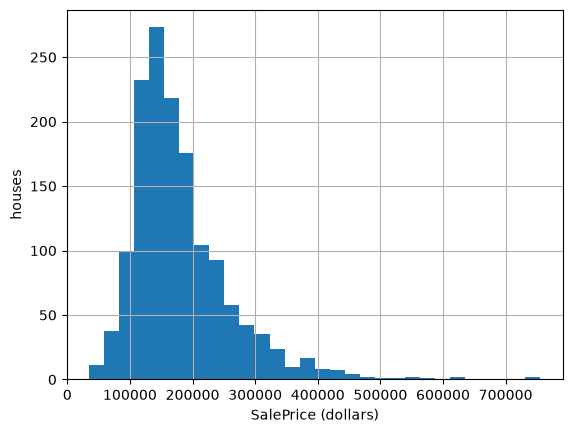

skew 1.88


In [4]:
sp.hist(bins=30)
plt.xlabel("SalePrice (dollars)")
plt.ylabel("houses")
plt.show()
print("skew", round(sp.skew(), 2))

## C2 · Missing values, relationships, outliers

### Step 4 · "Is the data complete?"

Translate: count missing values per column, sorted, and keep the columns with at least one. Then, for `PoolQC` and `GarageType`, check whether a missing value means "no pool" or "no garage": compare with `PoolArea == 0` and `GarageArea == 0`.

In [5]:
na = df.isna().sum().sort_values(ascending=False)
na = na[na > 0]
print(len(na), "columns with missing values")
print(na.head(8))
print("missing PoolQC with PoolArea 0:    ", (df["PoolQC"].isna() & (df["PoolArea"] == 0)).sum(),
      "of", df["PoolQC"].isna().sum())
print("missing GarageType with GarageArea 0:", (df["GarageType"].isna() & (df["GarageArea"] == 0)).sum(),
      "of", df["GarageType"].isna().sum())

19 columns with missing values
PoolQC         1453
MiscFeature    1406
Alley          1369
Fence          1179
MasVnrType      872
FireplaceQu     690
LotFrontage     259
GarageQual       81
dtype: int64
missing PoolQC with PoolArea 0:     1453 of 1453
missing GarageType with GarageArea 0: 81 of 81


### Step 5 · The word `None`

Read the file again with `pd.read_csv(PATH, keep_default_na=False)` and count each value of `MasVnrType`. How many of the "missing" values were really the word `None`?

In [6]:
raw = pd.read_csv(PATH, keep_default_na=False)
print(raw["MasVnrType"].value_counts())
none_word = (raw["MasVnrType"] == "None").sum()
truly_blank = (raw["MasVnrType"] == "").sum()
print(none_word, "were the word None;", truly_blank, "are really blank")

MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
             8
Name: count, dtype: int64
864 were the word None; 8 are really blank


### Step 6 · "What moves the price most?"

Translate: the correlation of every numeric column with `SalePrice`, sorted. Keep the top five.

In [7]:
corr = df.select_dtypes(include="number").corr()["SalePrice"].drop("SalePrice").sort_values(ascending=False)
corr.head(6).round(2)

OverallQual    0.79
GrLivArea      0.71
GarageCars     0.64
GarageArea     0.62
TotalBsmtSF    0.61
1stFlrSF       0.61
Name: SalePrice, dtype: float64

### Step 7 · Living area against price

Plot `GrLivArea` (living area in square feet) against `SalePrice`. Find the houses with more than 4,000 sq ft. How many are there, and what did the cheapest ones sell for? Look at their `SaleCondition`.

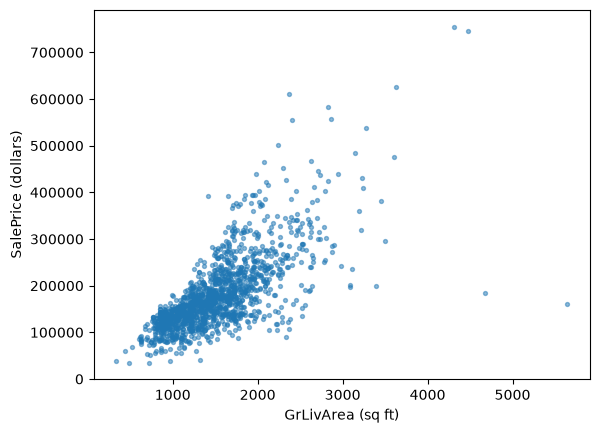

,GrLivArea,SalePrice,SaleCondition
523,4676,184750,Partial
691,4316,755000,Normal
1182,4476,745000,Abnorml
1298,5642,160000,Partial


In [8]:
plt.scatter(df["GrLivArea"], df["SalePrice"], s=8, alpha=0.5)
plt.xlabel("GrLivArea (sq ft)")
plt.ylabel("SalePrice (dollars)")
plt.show()
big = df[df["GrLivArea"] > 4000]
big[["GrLivArea", "SalePrice", "SaleCondition"]]

### Step 8 · "Which sale prices are unusual?"

Translate: Tukey's rule on `SalePrice`. Compute Q1 and Q3 with `quantile([0.25, 0.75])`, the IQR (Q3 − Q1), and the upper fence Q3 + 1.5 × IQR. Count the prices above it. Draw a box plot (`plt.boxplot(df["SalePrice"], orientation="horizontal")`) and find the fence on it.

Q1 129975, Q3 214000, IQR 84025, upper fence 340037.5, 61 prices above it


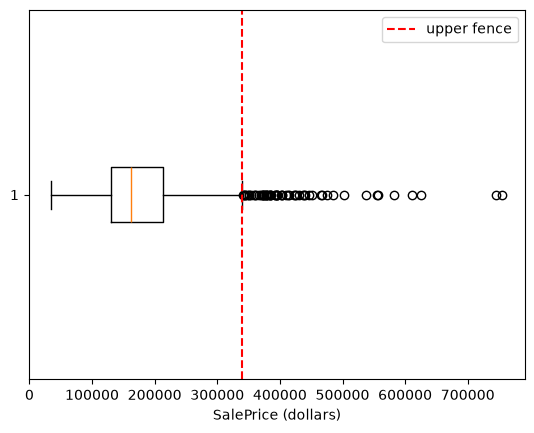

In [9]:
q1, q3 = sp.quantile([0.25, 0.75])
iqr = q3 - q1
fence = q3 + 1.5 * iqr
above = (sp > fence).sum()
print(f"Q1 {q1:.0f}, Q3 {q3:.0f}, IQR {iqr:.0f}, upper fence {fence:.1f}, {above} prices above it")
plt.boxplot(sp, orientation="horizontal")
plt.axvline(fence, color="red", linestyle="--", label="upper fence")
plt.xlabel("SalePrice (dollars)")
plt.legend()
plt.show()

## C3 · From findings to decisions

### Step 9 · The log of the price

Plot a histogram of `np.log(df["SalePrice"])` and print its skew.

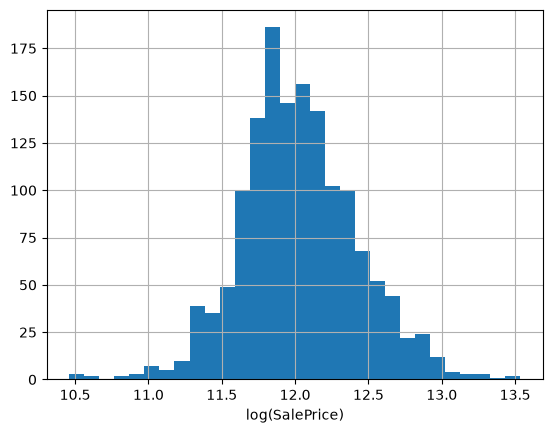

skew 0.12


In [10]:
np.log(sp).hist(bins=30)
plt.xlabel("log(SalePrice)")
plt.show()
print("skew", round(np.log(sp).skew(), 2))

### Step 10 · Price by quality and by neighborhood

Group by `OverallQual` (1 to 10) and print the median price for each level. Do the same for `Neighborhood` and name the cheapest and the dearest.

In [11]:
by_quality = df.groupby("OverallQual")["SalePrice"].median()
by_hood = df.groupby("Neighborhood")["SalePrice"].median().sort_values()
print(by_quality)
print("cheapest:", by_hood.index[0], by_hood.iloc[0], "| dearest:", by_hood.index[-1], by_hood.iloc[-1])

OverallQual
1      50150.0
2      60000.0
3      86250.0
4     108000.0
5     133000.0
6     160000.0
7     200141.0
8     269750.0
9     345000.0
10    432390.0
Name: SalePrice, dtype: float64
cheapest: MeadowV 88000.0 | dearest: NridgHt 315000.0


### Step 11 · Two columns that say almost the same thing

Hint: the garage. Print their correlation.

In [12]:
round(df["GarageCars"].corr(df["GarageArea"]), 2)

np.float64(0.88)

### Step 12 · Three feature decisions

One line each, in the form "Because *finding*, we will *action*." Example: "Because `PoolQC` is missing exactly where `PoolArea` is 0, we will fill it with `None` as a category of its own."

**Sample decisions** (D01 6.4 turns these into code):

- Because `SalePrice` has a long right tail and its log is close to symmetric, we will model `log(SalePrice)` and turn predictions back into dollars.
- Because the two cheapest houses over 4,000 sq ft were partial sales priced far below the trend, we will remove the houses over 4,000 sq ft before modeling, as De Cock recommends.
- Because the structural columns (`PoolQC`, `GarageType`, `Alley`, the basement columns) are missing exactly where the house has no pool, garage, alley or basement, we will fill them with `None` as a category of their own, and read the file so the word `None` in `MasVnrType` stays a category.
- Because `GarageCars` and `GarageArea` say almost the same thing (step 11), we will not read their coefficients one at a time.

## Check yourself

In [13]:
check = {
    "Step 1 · shape": df.shape,
    "Step 2 · mean": round(sp.mean()),
    "Step 2 · median": int(sp.median()),
    "Step 2 · min": int(sp.min()),
    "Step 2 · max": int(sp.max()),
    "Step 3 · skew": round(sp.skew(), 2),
    "Step 4 · columns with missing values": len(na),
    "Step 4 · missing PoolQC": int(na["PoolQC"]),
    "Step 4 · missing MiscFeature": int(na["MiscFeature"]),
    "Step 4 · missing Alley": int(na["Alley"]),
    "Step 4 · missing Fence": int(na["Fence"]),
    "Step 4 · missing MasVnrType": int(na["MasVnrType"]),
    "Step 4 · missing PoolQC with PoolArea 0": int((df["PoolQC"].isna() & (df["PoolArea"] == 0)).sum()),
    "Step 4 · missing GarageType with GarageArea 0": int((df["GarageType"].isna() & (df["GarageArea"] == 0)).sum()),
    "Step 5 · the word None": int(none_word),
    "Step 5 · really blank": int(truly_blank),
    "Step 6 · OverallQual": round(corr["OverallQual"], 2),
    "Step 6 · GrLivArea": round(corr["GrLivArea"], 2),
    "Step 6 · GarageCars": round(corr["GarageCars"], 2),
    "Step 6 · GarageArea": round(corr["GarageArea"], 2),
    "Step 6 · TotalBsmtSF": round(corr["TotalBsmtSF"], 2),
    "Step 6 · 1stFlrSF": round(corr["1stFlrSF"], 2),
    "Step 7 · houses over 4,000 sq ft": len(big),
    "Step 7 · their prices": ", ".join(str(p) for p in big["SalePrice"]),
    "Step 7 · their SaleCondition": ", ".join(big["SaleCondition"]),
    "Step 8 · Q1": int(q1),
    "Step 8 · Q3": int(q3),
    "Step 8 · IQR": int(iqr),
    "Step 8 · upper fence": int(fence),
    "Step 8 · prices above the fence": int(above),
    "Step 9 · skew of the log price": round(np.log(sp).skew(), 2),
    "Step 10 · median price by quality": ", ".join(f"{k} {int(v)}" for k, v in by_quality.items()),
    "Step 10 · cheapest neighborhood": f"{by_hood.index[0]} {int(by_hood.iloc[0])}",
    "Step 10 · dearest neighborhood": f"{by_hood.index[-1]} {int(by_hood.iloc[-1])}",
    "Step 11 · GarageCars and GarageArea": round(df["GarageCars"].corr(df["GarageArea"]), 2),
}
for label, value in check.items():
    print(f"{label:<48} {value}")

Step 1 · shape                                   (1460, 81)
Step 2 · mean                                    180921
Step 2 · median                                  163000
Step 2 · min                                     34900
Step 2 · max                                     755000
Step 3 · skew                                    1.88
Step 4 · columns with missing values             19
Step 4 · missing PoolQC                          1453
Step 4 · missing MiscFeature                     1406
Step 4 · missing Alley                           1369
Step 4 · missing Fence                           1179
Step 4 · missing MasVnrType                      872
Step 4 · missing PoolQC with PoolArea 0          1453
Step 4 · missing GarageType with GarageArea 0    81
Step 5 · the word None                           864
Step 5 · really blank                            8
Step 6 · OverallQual                             0.79
Step 6 · GrLivArea                               0.71
Step 6 · GarageCars     